In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import datetime as dt
import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter("ignore")

In [4]:
df = pd.read_csv('flipkart_product.csv', encoding='latin1')

In [5]:
df.head()

,ProductName,Price,Rate,Review,Summary
0,Candes 12 L Room/Personal Air Cooler?Ã¿?Ã¿(Whi...,"Æ??3,999",5,Super!,Great cooler.. excellent air flow and for this...
1,Candes 12 L Room/Personal Air Cooler?Ã¿?Ã¿(Whi...,"Æ??3,999",5,Awesome,Best budget 2 fit cooler. Nice cooling
2,Candes 12 L Room/Personal Air Cooler?Ã¿?Ã¿(Whi...,"Æ??3,999",3,Fair,The quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler?Ã¿?Ã¿(Whi...,"Æ??3,999",1,Useless product,Very bad product it's a only a fan
4,Candes 12 L Room/Personal Air Cooler?Ã¿?Ã¿(Whi...,"Æ??3,999",3,Fair,Ok ok product


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 189874 entries, 0 to 189873
Data columns (total 5 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   ProductName  189874 non-null  str  
 1   Price        189873 non-null  str  
 2   Rate         189873 non-null  str  
 3   Review       189870 non-null  str  
 4   Summary      189860 non-null  str  
dtypes: str(5)
memory usage: 7.2 MB


In [7]:
df.isna().sum()

ProductName     0
Price           1
Rate            1
Review          4
Summary        14
dtype: int64

In [8]:
df.nunique()

ProductName      812
Price            561
Rate               9
Review          1264
Summary        98343
dtype: int64

In [9]:
# Check for rows where Price can't be converted to float
def is_numeric(val):
    try:
        float(val.replace('₹', '').replace(',', ''))
        return True
    except:
        return False

# Find problematic rows
problematic_rows = df[~df['Price'].apply(is_numeric)]
print(problematic_rows[['Price']])

             Price
0        Æ??3,999
1        Æ??3,999
2        Æ??3,999
3        Æ??3,999
4        Æ??3,999
...            ...
189869  Ã¢âÂ¹142
189870  Ã¢âÂ¹142
189871  Ã¢âÂ¹142
189872  Ã¢âÂ¹142
189873         NaN

[189874 rows x 1 columns]


In [10]:
import pandas as pd
import re

# Function to clean Price
def clean_price(price):
    if pd.isna(price):  # Handle NaN values
        return None
    # Remove ₹ and commas, then keep only digits and decimal points
    price = str(price).replace('₹', '').replace(',', '')
    # Extract only numbers (and optionally a decimal point)
    cleaned = re.sub(r'[^0-9.]', '', price)
    return cleaned if cleaned else None  # Return None if no numbers found

# Apply cleaning
df['Price_Cleaned'] = df['Price'].apply(clean_price)

# Convert to float
df['Price_Cleaned'] = pd.to_numeric(df['Price_Cleaned'], errors='coerce')

# Check how many rows failed to convert
print("Rows with NaN Price after cleaning:", df['Price_Cleaned'].isna().sum())

Rows with NaN Price after cleaning: 1


In [11]:
# Drop rows where Price_Cleaned is NaN
df = df.dropna(subset=['Price_Cleaned'])

In [12]:
median_price = df['Price_Cleaned'].median()
df['Price_Cleaned'] = df['Price_Cleaned'].fillna(median_price)

In [13]:
# Check a sample of the cleaned prices
print(df[['Price', 'Price_Cleaned']].head(10))

       Price  Price_Cleaned
0  Æ??3,999         3999.0
1  Æ??3,999         3999.0
2  Æ??3,999         3999.0
3  Æ??3,999         3999.0
4  Æ??3,999         3999.0
5  Æ??3,999         3999.0
6  Æ??3,999         3999.0
7  Æ??3,999         3999.0
8  Æ??3,999         3999.0
9  Æ??3,999         3999.0


In [14]:
import re

# 1. Handle missing values
df = df.dropna(subset=['Summary'])  # Drop rows where Summary is missing
df['Review'] = df['Review'].fillna('No review')  # Fill missing Review with placeholder

# 2. Clean Price (remove ₹ and convert to numeric)
def clean_price(price):
    if pd.isna(price):
        return None
    price = str(price).replace('₹', '').replace(',', '')
    cleaned = re.sub(r'[^0-9.]', '', price)
    return cleaned if cleaned else None

df['Price_Cleaned'] = df['Price'].apply(clean_price)
df['Price_Cleaned'] = pd.to_numeric(df['Price_Cleaned'], errors='coerce')

# Drop or impute NaN prices
df = df.dropna(subset=['Price_Cleaned'])  # Dropping for simplicity

# 3. Clean Rate (convert to integer, handle odd values)
df['Rate'] = pd.to_numeric(df['Rate'], errors='coerce')
df = df.dropna(subset=['Rate'])
df['Rate'] = df['Rate'].astype(int)

# 4. Clean ProductName (remove weird characters)
df['ProductName'] = df['ProductName'].apply(lambda x: re.sub(r'[^a-zA-Z0-9\s]', '', x))

# 5. Basic text cleaning for Review and Summary
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df['Review'] = df['Review'].apply(clean_text)
df['Summary'] = df['Summary'].apply(clean_text)

# Verify the cleaned data
print(df[['Price', 'Price_Cleaned', 'Rate', 'ProductName']].head())

       Price  Price_Cleaned  Rate  \
0  Æ??3,999         3999.0     5   
1  Æ??3,999         3999.0     5   
2  Æ??3,999         3999.0     3   
3  Æ??3,999         3999.0     1   
4  Æ??3,999         3999.0     3   

                                         ProductName  
0  Candes 12 L RoomPersonal Air CoolerWhite Black...  
1  Candes 12 L RoomPersonal Air CoolerWhite Black...  
2  Candes 12 L RoomPersonal Air CoolerWhite Black...  
3  Candes 12 L RoomPersonal Air CoolerWhite Black...  
4  Candes 12 L RoomPersonal Air CoolerWhite Black...  


In [15]:
# Check unique values in Rate
print("Unique Rate values:", df['Rate'].unique())

Unique Rate values: [5 3 1 4 2]


In [16]:
# Map ratings to sentiment
def rate_to_sentiment(rate):
    if rate >= 4:
        return 'Positive'
    elif rate <= 2:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment_From_Rate'] = df['Rate'].apply(rate_to_sentiment)

# Check distribution of sentiment based on ratings
print(df['Sentiment_From_Rate'].value_counts())

Sentiment_From_Rate
Positive    148335
Negative     25841
Neutral      15680
Name: count, dtype: int64


In [23]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

# Download VADER lexicon
nltk.download('vader_lexicon', quiet=True)

# Initialize VADER
sia = SentimentIntensityAnalyzer()

# Apply VADER to Summary column
df['Sentiment_Score'] = df['Summary'].apply(lambda x: sia.polarity_scores(x)['compound'])

# Classify sentiment based on score
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['Sentiment_From_Text'] = df['Sentiment_Score'].apply(classify_sentiment)

# Check distribution of text-based sentiment
print(df['Sentiment_From_Text'].value_counts())

Sentiment_From_Text
Positive    150379
Negative     22023
Neutral      17454
Name: count, dtype: int64


In [18]:
# Create a cross-tabulation to compare the two
comparison = pd.crosstab(df['Sentiment_From_Rate'], df['Sentiment_From_Text'])
print(comparison)

# Calculate agreement rate
agreement = (df['Sentiment_From_Rate'] == df['Sentiment_From_Text']).mean()
print(f"Agreement between Rate-based and Text-based sentiment: {agreement:.2%}")

Sentiment_From_Text  Negative  Neutral  Positive
Sentiment_From_Rate                             
Negative                17327     5619      2895
Neutral                  2597     2643     10440
Positive                 2099     9192    137044
Agreement between Rate-based and Text-based sentiment: 82.70%


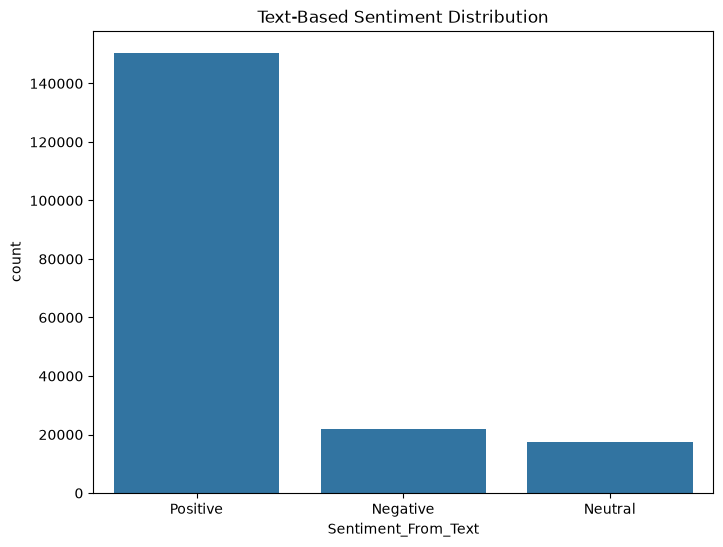

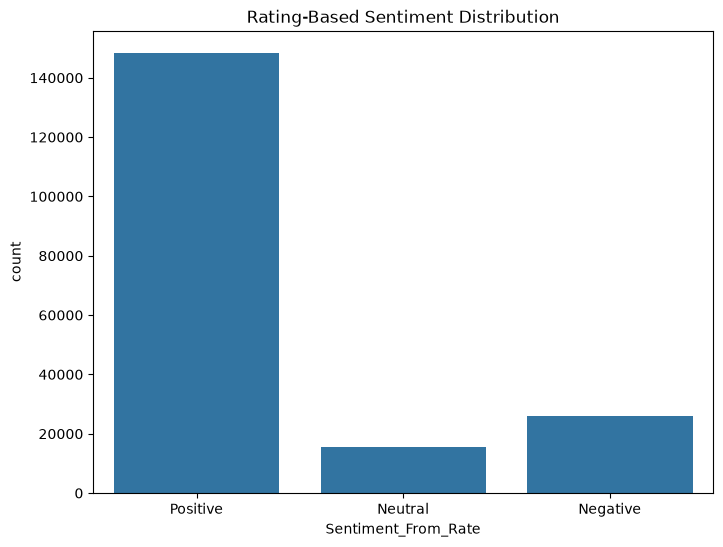

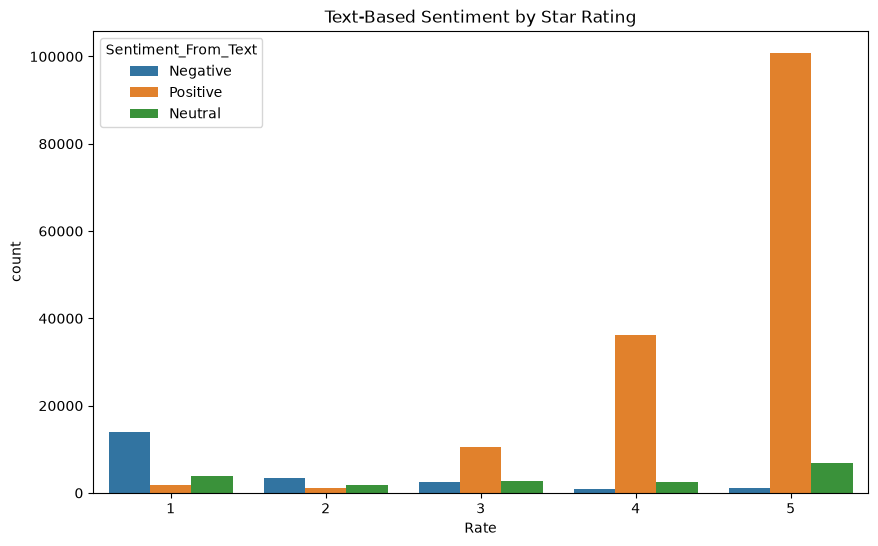

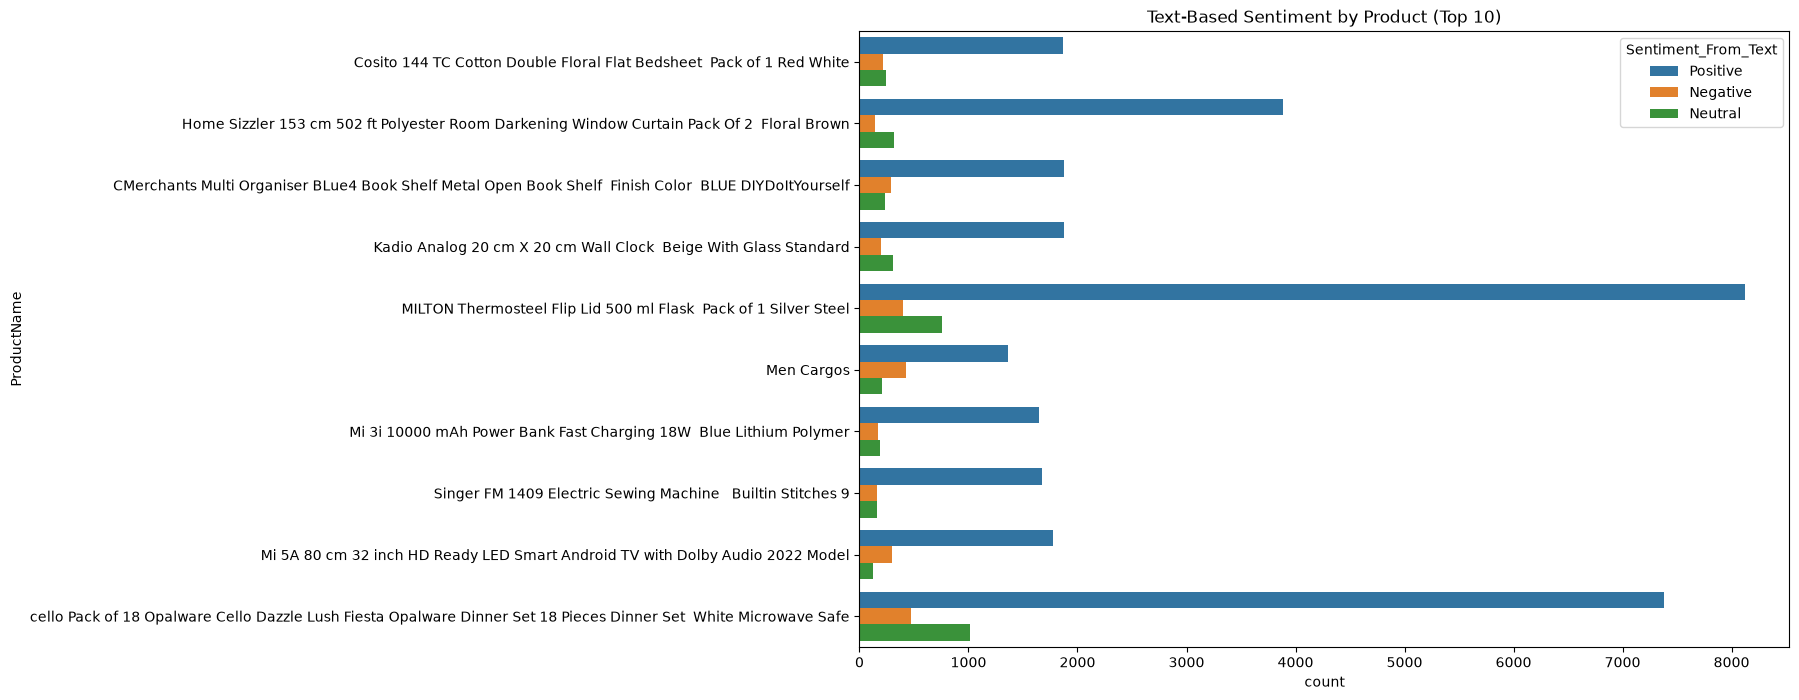

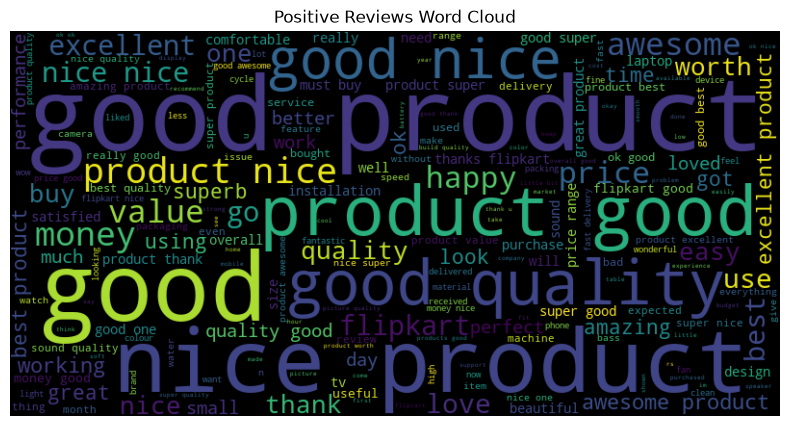

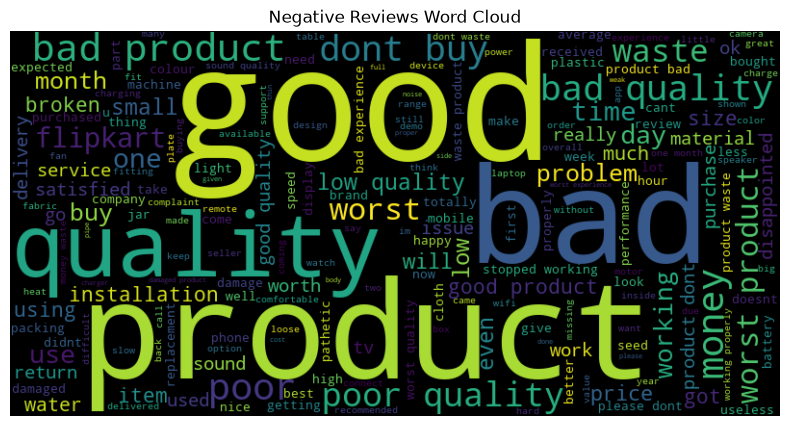

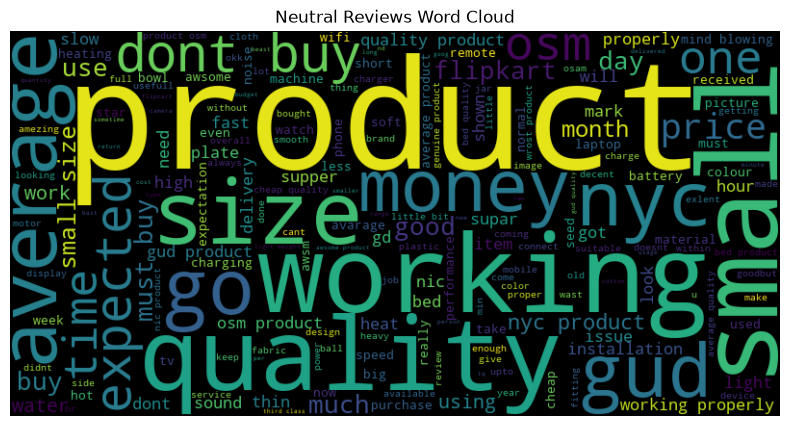

In [19]:
from wordcloud import WordCloud

# 1. Sentiment distribution (text-based)
plt.figure(figsize=(8, 6))
sns.countplot(x='Sentiment_From_Text', data=df)
plt.title('Text-Based Sentiment Distribution')
plt.show()

# 2. Sentiment distribution (rating-based)
plt.figure(figsize=(8, 6))
sns.countplot(x='Sentiment_From_Rate', data=df)
plt.title('Rating-Based Sentiment Distribution')
plt.show()

# 3. Sentiment by rating
plt.figure(figsize=(10, 6))
sns.countplot(x='Rate', hue='Sentiment_From_Text', data=df)
plt.title('Text-Based Sentiment by Star Rating')
plt.show()

# 4. Sentiment by product (top 10 products by review count)
top_products = df['ProductName'].value_counts().index[:10]
top_df = df[df['ProductName'].isin(top_products)]
plt.figure(figsize=(12, 8))
sns.countplot(y='ProductName', hue='Sentiment_From_Text', data=top_df)
plt.title('Text-Based Sentiment by Product (Top 10)')
plt.show()

# 5. Word clouds for positive and negative reviews
positive_reviews = ' '.join(df[df['Sentiment_From_Text'] == 'Positive']['Summary'])
negative_reviews = ' '.join(df[df['Sentiment_From_Text'] == 'Negative']['Summary'])
neutral_reviews = ' '.join(df[df['Sentiment_From_Text'] == 'Neutral']['Summary'])

# Positive word cloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400).generate(positive_reviews)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Reviews Word Cloud')
plt.show()

# Negative word cloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400).generate(negative_reviews)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Reviews Word Cloud')
plt.show()

# Neutral word cloud
plt.figure(figsize=(10, 5))
wordcloud = WordCloud(width=800, height=400).generate(neutral_reviews)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Neutral Reviews Word Cloud')
plt.show()

**Using RNNs for sentiment Analysis**

In [20]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical

# Use Summary column for analysis
texts = df['Summary'].values
labels = df['Rate'].apply(lambda x: 1 if x >= 4 else (0 if x == 3 else -1)).values

# Tokenization
max_words = 10000  # Vocabulary size
max_len = 100      # Maximum sequence length
tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

# Pad sequences
X = pad_sequences(sequences, maxlen=max_len)
y = to_categorical(np.array(labels) + 1, num_classes=3)  # Shift to 0, 1, 2 for categorical

# Split into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Define the model
model = Sequential()
model.add(Embedding(max_words, 100, input_length=max_len))  # Embedding layer
model.add(LSTM(64, return_sequences=False))                 # LSTM layer
model.add(Dropout(0.2))                                    # Dropout to prevent overfitting
model.add(Dense(3, activation='softmax'))                   # Output layer (3 classes: Neg, Neu, Pos)

# Compile the model
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
history = model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=5, batch_size=32, validation_split=0.2)

# Evaluate
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy:.4f}")

Epoch 1/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 148s 38ms/step - accuracy: 0.8884 - loss: 0.3447 - val_accuracy: 0.8995 - val_loss: 0.3052
Epoch 2/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 169s 44ms/step - accuracy: 0.9032 - loss: 0.2969 - val_accuracy: 0.9008 - val_loss: 0.3046
Epoch 3/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 170s 36ms/step - accuracy: 0.9085 - loss: 0.2799 - val_accuracy: 0.9001 - val_loss: 0.3079
Epoch 4/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 144s 38ms/step - accuracy: 0.9146 - loss: 0.2651 - val_accuracy: 0.9021 - val_loss: 0.3165
Epoch 5/5
3798/3798 ━━━━━━━━━━━━━━━━━━━━ 141s 37ms/step - accuracy: 0.9182 - loss: 0.2522 - val_accuracy: 0.8993 - val_loss: 0.3271
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 16s 14ms/step - accuracy: 0.8989 - loss: 0.3223
Test Accuracy: 0.8989


In [22]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Confusion matrix or classification report
from sklearn.metrics import classification_report
print(classification_report(y_test_classes, y_pred_classes, target_names=['Negative', 'Neutral', 'Positive']))

1187/1187 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step
              precision    recall  f1-score   support

    Negative       0.86      0.85      0.85      5242
     Neutral       0.44      0.21      0.29      3038
    Positive       0.93      0.98      0.95     29692

    accuracy                           0.90     37972
   macro avg       0.74      0.68      0.70     37972
weighted avg       0.88      0.90      0.89     37972

